In [32]:
import importlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

from scipy.optimize import differential_evolution
import pyswarms as ps

import auxiliar as aux

importlib.reload(aux)

<module 'auxiliar' from 'c:\\Users\\mateu\\OneDrive\\Área de Trabalho\\TimeSeriesEV\\auxiliar.py'>

# Load dos datasets

In [2]:
df_GT = pd.read_csv('./dataset/GlobalTemperatures.csv')
df_GT['year'] = df_GT['dt'].str.split('-').str[0].astype(int)
df_GT['dt'] = pd.to_datetime(df_GT['dt'])

df_USR = pd.read_csv('./dataset/USR.csv')
df_USR = df_USR[['Year', 'Month', 'Total Renewable Energy']].groupby(['Year', 'Month']).sum().reset_index()
df_USR['dt'] = df_USR['Year'].astype(str) + '-' + df_USR['Month'].astype(str)
df_USR['dt'] = pd.to_datetime(df_USR['dt'])

# Global Temperatures

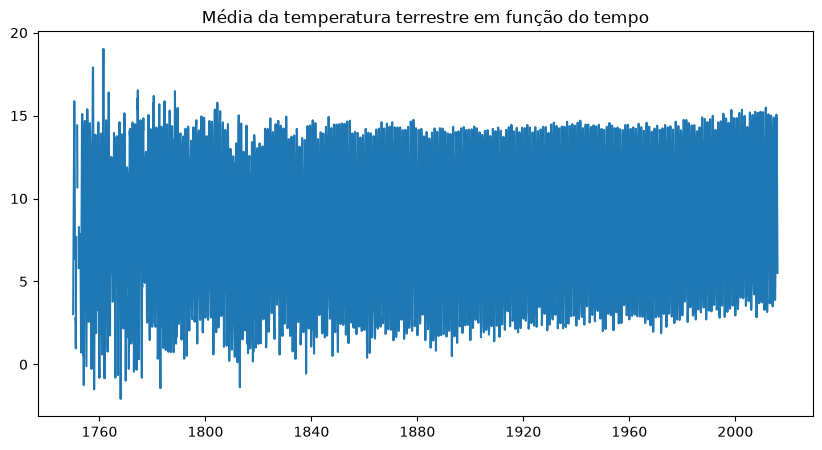

In [3]:
plt.figure(figsize=(10, 5))
plt.title('Média da temperatura terrestre em função do tempo')
plt.plot(df_GT['dt'], df_GT['LandAverageTemperature'])

Conforme discutido por Rohde et al. (2013), no artigo A New Estimate of the Average Earth Surface Land Temperature Spanning 1753 to 2011 (artigo referente ao dataset), o período entre 1753 e 1850 é caracterizado por quedas abruptas na temperatura média da superfície terrestre, coincidentes com episódios de atividade vulcânica conhecidos.

Esse comportamento é perceptível na visualização da série temporal, especialmente pela elevada frequência e amplitude das oscilações no período anterior a 1850, em contraste com o comportamento observado nos períodos subsequentes.

Dessa forma, optou-se por remover as observações anteriores a 1850 para a construção do modelo preditivo. Essa decisão busca reduzir a influência de variações abruptas associadas a eventos vulcânicos, que não são explicitamente representados pelas variáveis utilizadas no modelo, permitindo concentrar a modelagem em um período com comportamento temporal mais adequado aos objetivos da previsão.

Trecho no artigo:

"The period of 1753 to 1850 is marked by
sudden drops in land surface temperature that are coincident
with known volcanism; the response function is approximately
1.5 ± 0.5°C per 100 Tg of atmospheric sulfate. This volcanism,
combined with a simple proxy for anthropogenic effects (logarithm
of the CO2 concentration), reproduces much of the variationin the land surface temperature record"

In [4]:
df_GT = df_GT.query("year >= 1850")

# USR

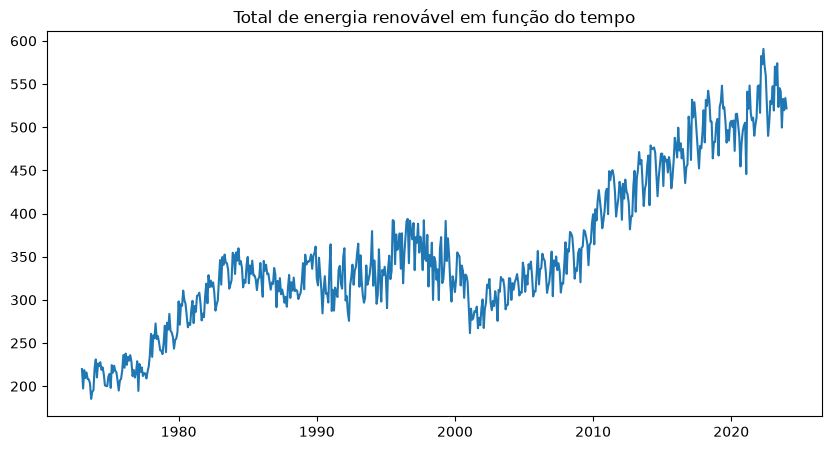

In [5]:
plt.figure(figsize=(10, 5))
plt.title('Total de energia renovável em função do tempo')
plt.plot(df_USR['dt'], df_USR['Total Renewable Energy'])

# Resultados dos algoritmos evolutivos

Para ambos os algoritmos evolutivos, PSO e DE, foi estabelecido um limite máximo de 200 gerações por execução. Adicionalmente, foi adotado um critério de parada antecipada por estagnação, segundo o qual a execução é interrompida caso não seja observada uma melhora significativa na melhor solução encontrada durante 20 gerações consecutivas. Dessa forma, embora o limite de 200 gerações permita um orçamento computacional máximo para a busca, o critério de estagnação possibilita encerrar antecipadamente execuções nas quais o algoritmo não apresenta progresso relevante, reduzindo o custo computacional sem exigir que todas as execuções atinjam o número máximo de gerações.

Os hiperparâmetros testados foram os seguintes:

In [6]:
configs_pso = [
    {
        "n_particles": 30,
        "iters": 200,
        "ftol_iter": 20,
        "c1": 1.49618,
        "c2": 1.49618,
        "w": 0.7298,
        "k": 3,
        "p": 2
    },
    {
        "n_particles": 30,
        "iters": 200,
        "ftol_iter": 20,
        "c1": 2.0,
        "c2": 2.0,
        "w": 0.7,
        "k": 3,
        "p": 2
    },
    {
        "n_particles": 30,
        "iters": 200,
        "ftol_iter": 20,
        "c1": 1.5,
        "c2": 2.0,
        "w": 0.7,
        "k": 5,
        "p": 2
    }
]

configs_de = [
    {
        "pop_size": 24,
        "iters": 200,
        "mutation": 0.5,
        "recombination": 0.5
    },
    {
        "pop_size": 24,
        "iters": 200,
        "mutation": 0.7,
        "recombination": 0.7
    },
    {
        "pop_size": 24,
        "iters": 200,
        "mutation": 0.9,
        "recombination": 0.9
    }
]


In [7]:
fitness_GT = aux.create_fitness(df_GT, value_col='LandAverageTemperature')
fitness_USR = aux.create_fitness(df_USR, value_col='Total Renewable Energy')

## PSO - temperaturas

Tabela dos parâmetros do PSO que gerou os melhores resultados

In [38]:
df_pso_temp = pd.read_csv('resultados/pso_temperature.csv')
df_pso_temp_grouped = df_pso_temp[['c1', 'c2', 'w', 'k', 'best_rmse']].groupby(['c1', 'c2', 'w', 'k']).median().sort_values('best_rmse')
df_pso_temp_grouped

,,,,best_rmse
c1,c2,w,k,
1.49618,1.49618,0.7298,3,0.386739
2.00000,2.00000,0.7000,3,0.402695
1.50000,2.00000,0.7000,5,0.409095


2026-11-20 14:20:51,985 - pyswarms.single.local_best - INFO - Optimize for 200 iters with {'c1': 1.49618, 'c2': 1.49618, 'w': 0.7298, 'k': 3, 'p': 2}
pyswarms.single.local_best:  10%|█         |21/200, best_cost=0.412
2026-11-20 14:22:55,750 - pyswarms.single.local_best - INFO - Optimization finished | best cost: 0.4123328090981917, best pos: [ 8.9611032  29.96482192  0.08902593]


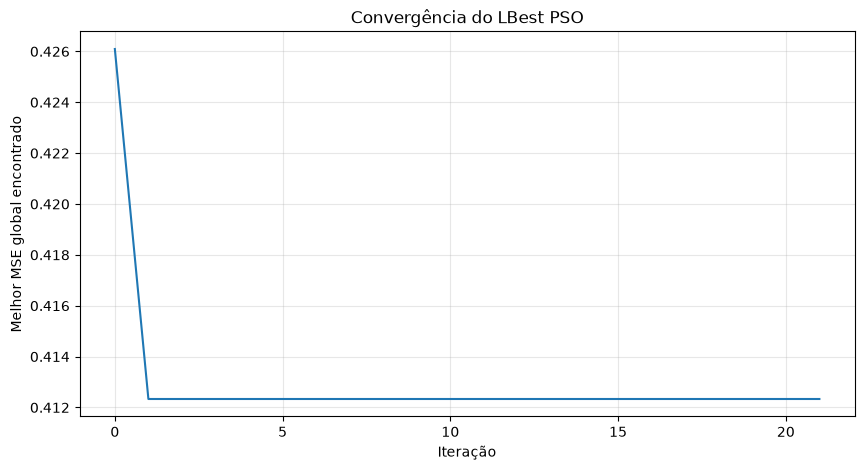

(np.float64(0.4123328090981917), 9, 30, np.float64(0.08902592674686866))

In [9]:
aux.PSO_lbest(fitness_GT, 30, 200, 20, 1.49618, 1.49618, 0.7298, 3, seed=1, plot=True)

In [39]:
filtro = (df_pso_temp[['c1', 'c2', 'w', 'k']] == df_pso_temp_grouped.index[0]).all(axis=1)
df_pso_temp = df_pso_temp[filtro]

Resultados de 10 execuções com os melhores parâmetros, sendo que k seria o lag da série, n o número de neurônios na camada escondida e learning_rate a taxa de aprendizado inicial da rede

In [40]:
net_params = df_pso_temp[['best_k', 'best_n', 'best_learning_rate', 'best_rmse']].sort_values('best_rmse')
net_params['test_error'] = [fitness_GT(param)['test_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params['train_error'] = [fitness_GT(param)['train_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
8,10,14,0.083581,0.371713,0.371713,0.382943
7,10,6,0.094258,0.377118,0.377118,0.387804
2,10,25,0.062313,0.378565,0.378565,0.373661
5,10,6,0.094482,0.379403,0.379403,0.387416
3,10,18,0.099774,0.386566,0.386566,0.386648
6,10,40,0.098587,0.386912,0.386912,0.373290
4,10,25,0.051636,0.405010,0.405010,0.402855
9,9,40,0.064687,0.419705,0.419705,0.393376
1,10,43,0.058289,0.422716,0.422716,0.379932
0,10,9,0.087270,0.451456,0.451456,0.396930


Resumo das estatísticas

In [41]:
net_params.describe()

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,9.900000,22.600000,0.079488,0.397916,0.397916,0.386485
std,0.316228,14.392899,0.018366,0.026019,0.026019,0.009552
min,9.000000,6.000000,0.051636,0.371713,0.371713,0.373290
25%,10.000000,10.250000,0.062906,0.378775,0.378775,0.380685
50%,10.000000,21.500000,0.085425,0.386739,0.386739,0.387032
75%,10.000000,36.250000,0.094426,0.416031,0.416031,0.391983
max,10.000000,43.000000,0.099774,0.451456,0.451456,0.402855


Pelas tabelas, é possível observar que:

<ul>
<li>nessas configurações do PSO, a fitness não varia muito entre as execuções, com um desvio padrão de ~0.026 e média ~0.397</li>
<li>ao contrário dos outros parâmetros da rede, o lag constantemente ficou em 10</li>
</ul>

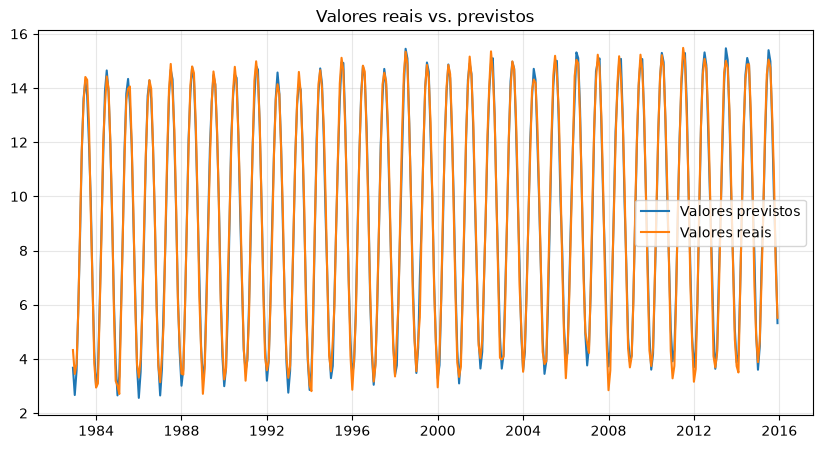

{'test_error': 0.371712877781577, 'train_error': 0.3829432987427838}

In [42]:
best_params = net_params.head(1)[['best_k', 'best_n', 'best_learning_rate']].values[0]
f_gt_plot = aux.create_fitness(df_GT, value_col='LandAverageTemperature', plot=True)
f_gt_plot(best_params)

## PSO - energia renovável

Tabela dos parâmetros do PSO que gerou os melhores resultados

In [43]:
df_pso_energ = pd.read_csv('resultados/pso_energy.csv')
df_pso_energ_grouped = df_pso_energ[['c1', 'c2', 'w', 'k', 'best_rmse']].groupby(['c1', 'c2', 'w', 'k']).median().sort_values('best_rmse')
df_pso_energ_grouped

,,,,best_rmse
c1,c2,w,k,
1.49618,1.49618,0.7298,3,19.185560
1.50000,2.00000,0.7000,5,19.397860
2.00000,2.00000,0.7000,3,19.465633


2026-11-20 14:23:01,587 - pyswarms.single.local_best - INFO - Optimize for 200 iters with {'c1': 1.49618, 'c2': 1.49618, 'w': 0.7298, 'k': 3, 'p': 2}
pyswarms.single.local_best:  22%|██▏       |44/200, best_cost=19  
2026-11-20 14:27:55,190 - pyswarms.single.local_best - INFO - Optimization finished | best cost: 18.965090923107354, best pos: [ 9.77666058 16.91683935  0.08158962]


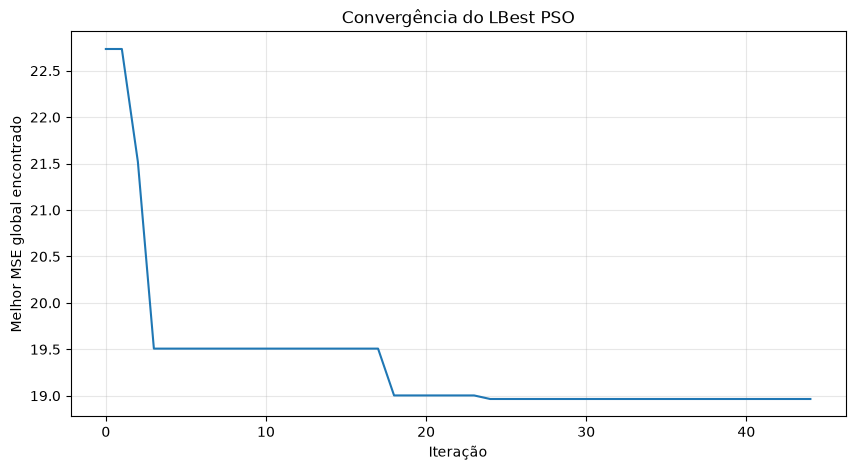

(np.float64(18.965090923107354), 10, 17, np.float64(0.08158962413678376))

In [15]:
aux.PSO_lbest(fitness_USR, 30, 200, 20, 1.49618, 1.49618, 0.7298, 3, plot=True)

In [44]:
filtro = (df_pso_energ[['c1', 'c2', 'w', 'k']] == df_pso_energ_grouped.index[0]).all(axis=1)
df_pso_energ = df_pso_energ[filtro]

Resultados de 10 execuções com os melhores parâmetros, sendo que k seria o lag da série, n o número de neurônios na camada escondida e learning_rate a taxa de aprendizado inicial da rede

In [45]:
net_params = df_pso_energ[['best_k', 'best_n', 'best_learning_rate', 'best_rmse']].sort_values('best_rmse')
net_params['test_error'] = [fitness_USR(param)['test_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params['train_error'] = [fitness_USR(param)['train_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
5,10,49,0.064050,17.320456,17.320456,14.807777
2,10,41,0.050171,17.841758,17.841758,15.335302
7,9,23,0.013990,18.514767,18.514767,15.517184
3,7,40,0.048206,18.519776,18.519776,14.188677
1,8,38,0.064611,19.114834,19.114834,13.326148
4,9,33,0.081239,19.256285,19.256285,14.521223
0,7,37,0.091857,19.314784,19.314784,14.213744
6,9,33,0.084661,19.326726,19.326726,15.805598
8,10,29,0.074670,19.424351,19.424351,14.389249
9,7,49,0.056979,19.438661,19.438661,15.300838


In [46]:
net_params.describe()

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
count,10.000000,10.00000,10.000000,10.000000,10.000000,10.000000
mean,8.600000,37.20000,0.063043,18.807240,18.807240,14.740574
std,1.264911,8.20298,0.022598,0.738926,0.738926,0.757466
min,7.000000,23.00000,0.013990,17.320456,17.320456,13.326148
25%,7.250000,33.00000,0.051873,18.516019,18.516019,14.257620
50%,9.000000,37.50000,0.064331,19.185560,19.185560,14.664500
75%,9.750000,40.75000,0.079597,19.323741,19.323741,15.326686
max,10.000000,49.00000,0.091857,19.438661,19.438661,15.805598


Pelas tabelas, é possível observar que:

<ul>
<li>nessas configurações do PSO, ao contrário do dataset de temperaturas, é possível ver que existe uma variação maior na escolha do lag, mantendo-se uma média alta de 8.6, mas com desvio padrão de ~1.264</li>
<li>apesar de ainda ter uma variação considerável, é possível perceber que as quantidades de neurônios na camada escondida foram constantemente mais altas, tendo 37.5 no percential 50% e 40.75 no 75% e uma amplitude menor 49 - 23 (max - min)</li>
</ul>

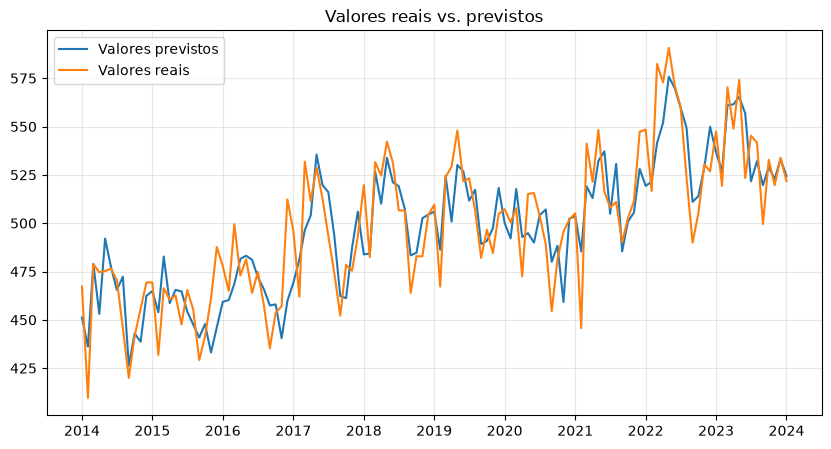

{'test_error': 17.320455717333704, 'train_error': 14.807777093568738}

In [47]:
best_params = net_params.head(1)[['best_k', 'best_n', 'best_learning_rate']].values[0]
f_usr_plot = aux.create_fitness(df_USR, value_col='Total Renewable Energy', plot=True)
f_usr_plot(best_params)

## DE - temperaturas

In [48]:
df_de_temp = pd.read_csv('resultados/de_temperature.csv')
df_de_temp_grouped = df_de_temp[['pop_size', 'recombination', 'mutation', 'best_rmse']].groupby(['pop_size', 'recombination', 'mutation']).median().sort_values('best_rmse')
df_de_temp_grouped

best_rmse
pop_size recombination mutation           
24       0.5           0.5        0.367999
         0.7           0.7        0.369042
         0.9           0.9        0.379470

differential_evolution step 1: f(x)= 0.4399073998646887
differential_evolution step 2: f(x)= 0.43459166195389565
differential_evolution step 3: f(x)= 0.43459166195389565
differential_evolution step 4: f(x)= 0.4051382431445618
differential_evolution step 5: f(x)= 0.4051382431445618
differential_evolution step 6: f(x)= 0.4051382431445618
differential_evolution step 7: f(x)= 0.37994225631623985
differential_evolution step 8: f(x)= 0.37994225631623985
differential_evolution step 9: f(x)= 0.37399332299665833
differential_evolution step 10: f(x)= 0.37399332299665833
differential_evolution step 11: f(x)= 0.37399332299665833
differential_evolution step 12: f(x)= 0.37399332299665833
differential_evolution step 13: f(x)= 0.37399332299665833
differential_evolution step 14: f(x)= 0.37399332299665833
differential_evolution step 15: f(x)= 0.37399332299665833
differential_evolution step 16: f(x)= 0.37399332299665833
differential_evolution step 17: f(x)= 0.37399332299665833
differential_evolution step

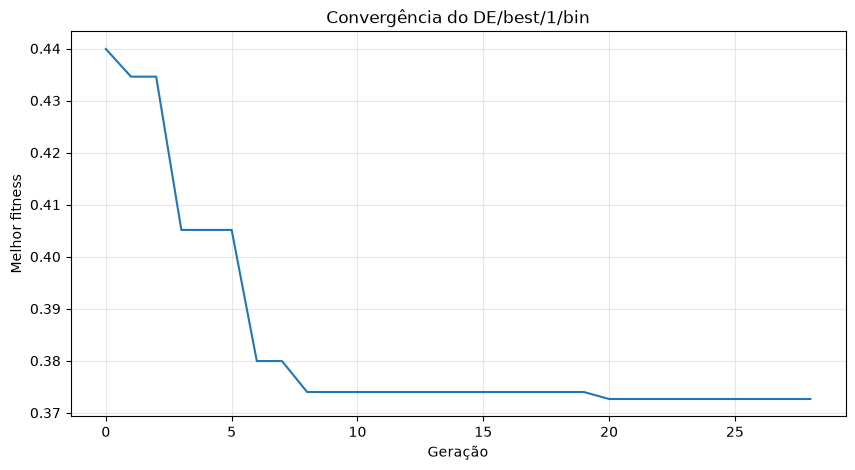

(np.float64(0.3726525798364785), 10, 14, np.float64(0.07520886980439424))

In [21]:
aux.DE_DEBEST1(fitness_GT, 24, 200, 0.5, 0.5, plot=True)

In [49]:
filtro = (df_de_temp[['pop_size', 'recombination', 'mutation']] == df_de_temp_grouped.index[0]).all(axis=1)
df_de_temp = df_de_temp[filtro]

Resultados de 10 execuções com os melhores parâmetros, sendo que k seria o lag da série, n o número de neurônios na camada escondida e learning_rate a taxa de aprendizado inicial da rede

In [50]:
net_params = df_de_temp[['best_k', 'best_n', 'best_learning_rate', 'best_rmse']].sort_values('best_rmse')
net_params['test_error'] = [fitness_GT(param)['test_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params['train_error'] = [fitness_GT(param)['train_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
4,10,30,0.097328,0.362823,0.362823,0.365839
6,10,25,0.083343,0.363122,0.363122,0.381853
8,10,30,0.097256,0.364201,0.364201,0.364938
0,10,25,0.079520,0.365413,0.365413,0.389039
5,10,25,0.060040,0.366608,0.366608,0.364273
9,10,14,0.062668,0.369390,0.369390,0.371876
2,10,14,0.062860,0.369743,0.369743,0.371011
7,10,25,0.081734,0.370850,0.370850,0.386508
1,10,25,0.081662,0.375881,0.375881,0.384341
3,10,25,0.059708,0.376687,0.376687,0.372976


In [51]:
net_params.describe()

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
count,10.0,10.000000,10.000000,10.000000,10.000000,10.000000
mean,10.0,23.800000,0.076612,0.368472,0.368472,0.375265
std,0.0,5.553777,0.014548,0.004968,0.004968,0.009387
min,10.0,14.000000,0.059708,0.362823,0.362823,0.364273
25%,10.0,25.000000,0.062716,0.364504,0.364504,0.367132
50%,10.0,25.000000,0.080591,0.367999,0.367999,0.372426
75%,10.0,25.000000,0.082941,0.370573,0.370573,0.383719
max,10.0,30.000000,0.097328,0.376687,0.376687,0.389039


Pelas tabelas, é possível observar que:

<ul>
<li>nessas configurações do DE, todas as execuções chegaram num lag de 10. além disso, os números de neurônios na camada escondida ficaram bem concentrados entre 25-30.</li>
<li>a fitness (rmse) se manteve bastante estável entre as execuções, com um desvio padrão de ~0.0049 com média de 0.3684</li>
</ul>

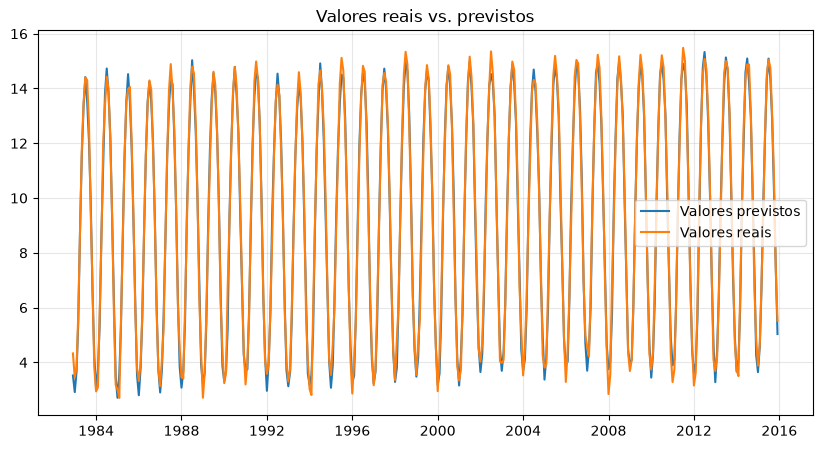

{'test_error': 0.36282341119504263, 'train_error': 0.3658392867746941}

In [52]:
best_params = net_params.head(1)[['best_k', 'best_n', 'best_learning_rate']].values[0]
f_gt_plot = aux.create_fitness(df_GT, value_col='LandAverageTemperature', plot=True)
f_gt_plot(best_params)

## DE - energia

In [53]:
df_de_energ = pd.read_csv('resultados/de_energy.csv')
df_de_energ_grouped = df_de_energ[['pop_size', 'recombination', 'mutation', 'best_rmse']].groupby(['pop_size', 'recombination', 'mutation']).median().sort_values('best_rmse')
df_de_energ_grouped

best_rmse
pop_size recombination mutation           
24       0.5           0.5       17.502747
         0.9           0.9       17.835583
         0.7           0.7       18.095484

differential_evolution step 1: f(x)= 20.721622764556162
differential_evolution step 2: f(x)= 20.721622764556162
differential_evolution step 3: f(x)= 20.721622764556162
differential_evolution step 4: f(x)= 19.840403372595876
differential_evolution step 5: f(x)= 19.840403372595876
differential_evolution step 6: f(x)= 19.840403372595876
differential_evolution step 7: f(x)= 19.840403372595876
differential_evolution step 8: f(x)= 19.840403372595876
differential_evolution step 9: f(x)= 19.687807640876652
differential_evolution step 10: f(x)= 19.687807640876652
differential_evolution step 11: f(x)= 19.687807640876652
differential_evolution step 12: f(x)= 19.687807640876652
differential_evolution step 13: f(x)= 19.687807640876652
differential_evolution step 14: f(x)= 19.687807640876652
differential_evolution step 15: f(x)= 19.687807640876652
differential_evolution step 16: f(x)= 19.378885646837738
differential_evolution step 17: f(x)= 19.378885646837738
differential_evolution step 18: f(x)= 19

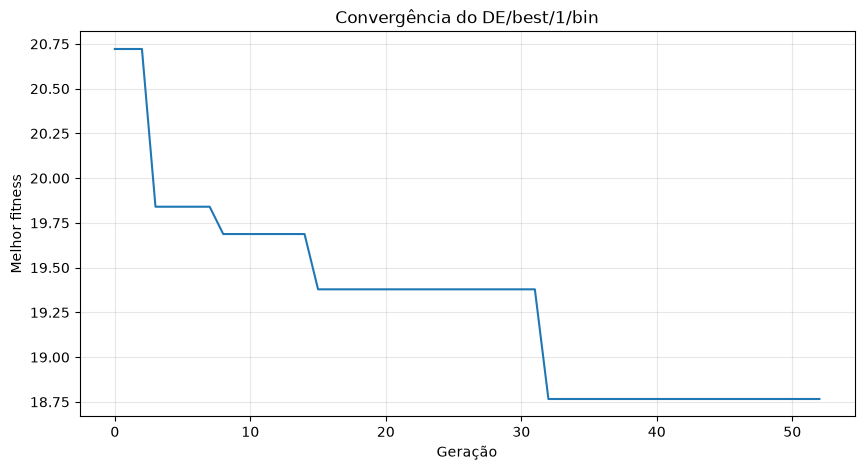

(np.float64(18.766174608361744), 7, 40, np.float64(0.05924176390823569))

In [27]:
aux.DE_DEBEST1(fitness_USR, 24, 200, 0.5, 0.5, plot=True)

In [54]:
filtro = (df_de_energ[['pop_size', 'recombination', 'mutation']] == df_de_energ_grouped.index[0]).all(axis=1)
df_de_energ = df_de_energ[filtro]

In [55]:
net_params = df_de_energ[['best_k', 'best_n', 'best_learning_rate', 'best_rmse']].sort_values('best_rmse')
net_params['test_error'] = [fitness_USR(param)['test_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params['train_error'] = [fitness_USR(param)['train_error'] for param in net_params[['best_k', 'best_n', 'best_learning_rate']].values]
net_params

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
1,8,48,0.073700,16.465014,16.465014,14.088799
6,9,23,0.016110,17.085327,17.085327,14.640480
3,9,23,0.016109,17.129874,17.129874,14.639137
5,9,23,0.016548,17.174731,17.174731,14.570635
4,10,43,0.064223,17.219318,17.219318,14.284272
0,9,23,0.016098,17.786176,17.786176,14.550617
7,9,23,0.020034,17.813264,17.813264,14.302275
2,9,23,0.016008,17.845325,17.845325,14.655437
9,8,48,0.071803,18.007535,18.007535,15.003315
8,8,40,0.030922,19.090890,19.090890,14.109546


In [56]:
net_params.describe()

,best_k,best_n,best_learning_rate,best_rmse,test_error,train_error
count,10.000000,10.00000,10.000000,10.000000,10.000000,10.000000
mean,8.800000,31.70000,0.034155,17.561745,17.561745,14.484451
std,0.632456,11.46056,0.025192,0.716039,0.716039,0.284583
min,8.000000,23.00000,0.016008,16.465014,16.465014,14.088799
25%,8.250000,23.00000,0.016109,17.141088,17.141088,14.288772
50%,9.000000,23.00000,0.018291,17.502747,17.502747,14.560626
75%,9.000000,42.25000,0.055898,17.837310,17.837310,14.640144
max,10.000000,48.00000,0.073700,19.090890,19.090890,15.003315


Pelas tabelas, é possível observar que:

<ul>
<li>um indivíduo parece se repetir bastante com k=9, n=23 e lr=~0.016</li>
</ul>

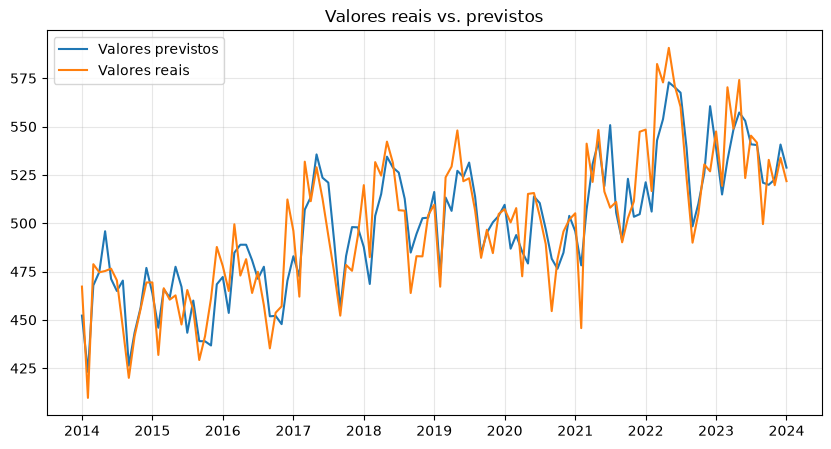

{'test_error': 16.465014233199103, 'train_error': 14.088798888142518}

In [57]:
best_params = net_params.head(1)[['best_k', 'best_n', 'best_learning_rate']].values[0]
f_usr_plot = aux.create_fitness(df_USR, value_col='Total Renewable Energy', plot=True)
f_usr_plot(best_params)

# Conclusões

Uma interpretação plausível para as diferenças de desempenho entre os datasets está relacionada tanto à quantidade de observações disponíveis quanto às características estruturais das séries temporais.

Primeiramente, observa-se uma diferença considerável na extensão dos históricos. Embora a base de temperatura contenha registros desde meados do século XVIII, o período efetivamente utilizado na experimentação compreende aproximadamente 1850 a 2015, totalizando cerca de 165 anos. Em contrapartida, a base de energia renovável abrange um intervalo inferior a 100 anos, entre 1973 e 2024. Essa diferença pode influenciar o desempenho dos modelos, uma vez que um histórico mais extenso proporciona maior quantidade de observações para o treinamento da rede neural, permitindo que ela identifique padrões temporais a partir de um conjunto mais abrangente de dados.

Além disso, as séries apresentam características visuais distintas. A série de temperatura parece exibir um comportamento relativamente mais regular, com oscilações em torno de uma tendência de longo prazo relativamente gradual. Já a série de energia renovável aparenta apresentar maior complexidade e variabilidade, com alterações mais acentuadas em seu comportamento ao longo do tempo. Uma possível explicação está na natureza dos fenômenos representados: enquanto a temperatura terrestre é influenciada por processos climáticos e físicos, que podem produzir padrões de longo prazo relativamente persistentes, a evolução da produção ou do consumo de energia renovável está sujeita a uma combinação de fatores socioeconômicos, tecnológicos, regulatórios e políticos. Esses fatores podem introduzir mudanças de tendência e maior irregularidade na série, dificultando a identificação de padrões temporais consistentes por modelos baseados exclusivamente em observações passadas.

Dessa forma, a maior dificuldade de previsão observada na série de energia renovável pode estar associada à combinação de um histórico mais curto e de uma estrutura temporal aparentemente mais variável e complexa. Essas características podem limitar a capacidade de generalização das redes neurais, independentemente do algoritmo evolutivo utilizado na otimização dos hiperparâmetros.

Na comparação entre os algoritmos evolutivos, o Differential Evolution (DE) apresentou desempenho ligeiramente superior ao PSO-LBest, com erros de previsão um pouco menores. Além disso, os resultados do DE demonstraram menor variabilidade entre as diferentes execuções, sugerindo maior estabilidade e consistência no processo de otimização. Embora as diferenças não indiquem uma superioridade expressiva, os resultados observados apontam para uma vantagem leve do DE tanto em desempenho quanto em robustez.

Por fim, em relação aos hiperparâmetros das redes neurais, observou-se uma tendência de escolha de ordens do modelo (lags) próximas ao limite superior estabelecido, frequentemente atingindo o valor máximo de 10. Esse comportamento sugere que, para ambas as séries, a utilização de um histórico mais amplo de observações pode favorecer o desempenho preditivo. Por outro lado, o número de neurônios na camada escondida apresentou maior variabilidade entre as execuções e os algoritmos. Destaca-se, ainda, que, para o dataset de energia renovável, tanto o PSO quanto o DE tenderam a selecionar arquiteturas com maior número de neurônios do que aquelas escolhidas para o dataset de temperatura. Esse resultado pode estar relacionado à maior complexidade dos padrões temporais da série de energia, demandando maior capacidade representacional da rede para capturar suas relações.